<a href="https://colab.research.google.com/github/Rojas-1402/ml-course/blob/main/Copia_de_01_actividad_numpy_pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capítulo 3 · Actividad: análisis de datos con NumPy, pandas y matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/01_actividad_numpy_pandas.ipynb)

En esta actividad haces de **analista de datos**: vas a responder preguntas sobre datos reales con **NumPy** y **pandas**, y después los visualizarás con **matplotlib** y **seaborn**. Lo importante no es solo que el código funcione, sino que **sepas interpretar los resultados**.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia. Si editas el original tendrás conflictos al sincronizar tu fork.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```
3. Ten a mano las notebooks de clase de `notebooks/lectures/chapter_03/`: `01_numpy`, `02_pandas` y `03_matplotlib`.

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Puedes añadir todas las celdas que necesites.
- En las celdas ✍️ responde con tus palabras y **apoya tus respuestas con números** de tus resultados.
- En las partes 1 y 2, las 💡 **pistas** te recuerdan funciones. Si una función no salió en clase, la pista explica cómo usarla. La parte 3 no tiene pistas.
- Al terminar, ejecuta **Kernel → Restart & Run All** y comprueba que todo funciona de arriba abajo.

| Parte | Datos | Herramienta |
|---|---|---|
| 1. La cafetería | ventas de un mes (generadas en la notebook) | NumPy |
| 2. Las propinas | `data/tips.csv` | pandas (+ un poco de NumPy) |
| 3. Visualización | cafetería, propinas y `data/penguins.csv` | matplotlib y seaborn |

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: /content/data


In [ ]:
import os

# Ruta completa del archivo que queremos verificar
ruta_archivo = DATA_DIR / "tips.csv"

# Verificamos si existe
si_existe = os.path.exists(ruta_archivo)
print(f"¿Existe el archivo '{ruta_archivo.name}' en la ruta? {si_existe}")

# Listamos el contenido de la carpeta data si existe
if os.path.exists(DATA_DIR):
    print("Contenido de la carpeta data:", os.listdir(DATA_DIR))
else:
    print("La carpeta data no existe.")

¿Existe el archivo 'tips.csv' en la ruta? True
Contenido de la carpeta data: ['california_housing.csv', 'viviendas.csv', 'iris.csv', 'titanic.csv', 'tips.csv', 'breast_cancer.csv', 'penguins.csv', 'viviendas_sucio.csv']


In [ ]:
# Descargamos los datos del repositorio usando el script oficial del curso
import os

# Instalamos uv si no estuviera y corremos el script de descarga del repo
!pip install uv -q
!uv run python ml-course/scripts/download_data.py

# Creamos la carpeta data local en /content/data y copiamos los archivos recién descargados
!mkdir -p /content/data
!cp -r ml-course/data/* /content/data/

# Verificamos de nuevo si ahora el archivo ya existe
from pathlib import Path
DATA_DIR = Path("/content/data")
if (DATA_DIR / "tips.csv").exists():
    print("¡Listo! El archivo 'tips.csv' se ha descargado y copiado correctamente en la carpeta 'data'.")
else:
    print("Hubo un problema y el archivo no se encuentra en 'data'.")

✔ data/viviendas.csv               600 filas × 8 columnas
✔ data/viviendas_sucio.csv         612 filas × 10 columnas
✔ data/titanic.csv                 891 filas × 15 columnas
✔ data/penguins.csv                344 filas × 7 columnas
✔ data/tips.csv                    244 filas × 7 columnas
✔ data/iris.csv                    150 filas × 5 columnas
✔ data/breast_cancer.csv           569 filas × 31 columnas
✔ data/california_housing.csv    20640 filas × 9 columnas
¡Listo! El archivo 'tips.csv' se ha descargado y copiado correctamente en la carpeta 'data'.


---
## Parte 1 · La cafetería ☕ (NumPy)

Una cafetería vende 5 productos y ha registrado cuántas unidades vendió de cada uno durante **4 semanas** (28 días, de lunes a domingo). La dueña quiere saber cuánto gana, qué días van mejor y qué producto le conviene más.

Ejecuta la siguiente celda para generar los datos. **No hace falta que la modifiques ni que entiendas cada línea.**

In [ ]:
# Datos de la cafetería (no hace falta modificar esta celda)
rng = np.random.default_rng(42)

productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])       # precio de cada producto, en $

# Unidades vendidas cada día: los fines de semana se vende un 50% más
dia_semana = np.tile(np.arange(7), 4)                # 0 = lunes, ..., 6 = domingo
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])     # ventas esperadas por día y producto
ventas_planas = rng.poisson(promedio).ravel()         # ¡todo en una sola fila!

print(ventas_planas[:10], "...")
print("Número de valores:", ventas_planas.size)

[35 28  7 16 13 29 16 10 18 11] ...
Número de valores: 140


### Ejercicio 1 · Dar forma a los datos

`ventas_planas` tiene 140 números seguidos: primero las ventas de los 5 productos del día 1, después las del día 2, y así sucesivamente.

a) Crea una matriz `ventas` con forma `(28, 5)`: una **fila por día** y una **columna por producto** (en el mismo orden que `productos`).

b) Imprime su `shape`, `ndim`, `size` y `dtype`.

c) ¿Cuántos cafés se vendieron el primer día? Comprueba que coincide con `ventas_planas[0]`.

> 💡 **Pista:** `reshape`.

In [ ]:
# Tu código aquí
ventas = ventas_planas.reshape (28, 5)
print("shape:", ventas.shape)
print("ndim:", ventas.ndim)
print("size:", ventas.size)
print("dtype:", ventas.dtype)

cafes_primer_dia = ventas [0, 0]
print("cafes vendidos el primer dia (matriz):", cafes_primer_dia)
print("Coincide con ventas_planas[0]:", cafes_primer_dia== ventas_planas[0])


shape: (28, 5)
ndim: 2
size: 140
dtype: int64
cafes vendidos el primer dia (matriz): 35
Coincide con ventas_planas[0]: True


### Ejercicio 2 · Indexación

Obtén, usando índices y *slicing* sobre `ventas`:

a) Las ventas de todos los productos el **primer día**.

b) Las ventas de **latte** (columna 1) durante todo el mes.

c) Las ventas de la **última semana** (los últimos 7 días). Comprueba que su forma es `(7, 5)`.

d) Las ventas de **croissant y sándwich** (las dos últimas columnas) durante la **primera semana**.

> 💡 **Pista:** `M[filas, columnas]`. Recuerda que los índices negativos cuentan desde el final.

In [ ]:
# a) ventas de todos los productos el primer día
ventas_primer_dia = ventas[0, :]
print("a) Ventas primer día:", ventas_primer_dia)

# b) ventas de latte (columna 1) durante todo el mes
ventas_latte = ventas[:, 1]
print("b) Ventas de latte todo el mes:", ventas_latte)

# c) ventas de la última semana (últimos 7 días) y comprobación de su forma
ultima_semana = ventas[-7:, :]
print("c) Ventas última semana:\n", ultima_semana)
print("   Forma (shape):", ultima_semana.shape)

# d) Las ventas de croissant y sándwich (últimas 2 columnas) durante la primera semana
croissant_sandwich_primera_semana = ventas[:7, -2:]
print("d) Croissant y sándwich primera semana:\n", croissant_sandwich_primera_semana)

a) Ventas primer día: [35 28  7 16 13]
b) Ventas de latte todo el mes: [28 16 17 21 17 29 37 16 23 25 22 19 29 39 24 19 18 22 30 44 27 14 31 21
 30 26 32 45]
c) Ventas última semana:
 [[22 14 11 20  9]
 [34 31 12 27  7]
 [26 21 17 23  7]
 [35 30  3  9 10]
 [23 26 16 21  8]
 [38 32 20 21 11]
 [49 45 18 27  9]]
   Forma (shape): (7, 5)
d) Croissant y sándwich primera semana:
 [[16 13]
 [18 11]
 [17 10]
 [15  8]
 [17  8]
 [22 14]
 [29 12]]


### Ejercicio 3 · Ingresos

a) Calcula la matriz `ingresos` (forma `(28, 5)`): lo que se ingresó por cada producto cada día.

b) ¿Cuánto ingresó la cafetería en todo el mes?

c) Crea `ingreso_diario`, un array con el ingreso total de **cada día** (forma `(28,)`).

d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?

> 💡 **Pistas:**
> - `ventas * precios` multiplica **cada fila** de `ventas` por el vector `precios`, elemento a elemento: la columna del café por 1.5, la del latte por 2.8… (este mecanismo se llama *broadcasting*).
> - `M.sum()` suma todo. `M.sum(axis=1)` suma **cada fila** y devuelve un resultado por fila; `M.sum(axis=0)` suma **cada columna**.

In [ ]:
# a) Calcula la matriz ingresos (forma (28, 5))
ingresos = ventas * precios

# b) ¿Cuánto ingresó la cafetería en todo el mes?
ingresos_totales_mes = ingresos.sum()
print("b) Ingresos totales del mes: $", ingresos_totales_mes)

# c) Crea ingreso_diario, un array con el ingreso total de cada día (forma (28,))
ingreso_diario = ingresos.sum(axis=1)
print("c) Ingreso diario:", ingreso_diario)

# d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?
ingreso_medio = ingreso_diario.mean()
ingreso_max = ingreso_diario.max()
ingreso_min = ingreso_diario.min()

print("d)")
print("Ingreso diario medio: $", ingreso_medio)
print("Ingreso diario máximo: $", ingreso_max)
print("Ingreso diario mínimo: $", ingreso_min)

b) Ingresos totales del mes: $ 6342.5
c) Ingreso diario: [229.8 185.8 194.1 179.1 178.2 291.7 319.1 188.9 183.2 198.3 204.6 191.3
 320.7 317.5 181.9 174.1 176.6 196.8 229.  337.3 279.9 165.9 237.7 195.7
 203.1 204.5 262.1 315.6]
d)
Ingreso diario medio: $ 226.5178571428572
Ingreso diario máximo: $ 337.29999999999995
Ingreso diario mínimo: $ 165.89999999999998


### Ejercicio 4 · Días buenos y días flojos

Usa este array con el número de cada día (del 1 al 28):
```python
dias = np.arange(1, 29)
```

a) Crea una máscara con los días cuyo ingreso supera el **ingreso diario medio** y muestra **qué días** fueron.

b) ¿**Cuántos** días fueron?

c) Crea un array que diga `"bueno"` o `"flojo"` para cada día, según si supera o no la media.

d) Calcula `dias[mascara] % 7` (el resto de dividir entre 7). El día 1 fue lunes, así que un resto de **6** es sábado y un resto de **0** es domingo. ¿Qué tienen en común los días buenos?

> 💡 **Pistas:** `.sum()` sobre una máscara cuenta los `True`, porque `True` vale 1 y `False` vale 0. Para c), `np.where`.

In [ ]:
dias =np.arange(1, 29)
mascara = ingreso_diario > ingreso_medio
dias_buenos = dias[mascara]

print ("a)")
print("Dias que los ingresos superan la media:", dias_buenos)

num_dias_buenos = mascara.sum()
print("b)")
print("Dias buenos:", num_dias_buenos)

etiqueta_dias = np.where(mascara, "bueno", "flojo")
print("c)")
print("Estado de cada dia:", etiqueta_dias)

resto_dias_buenos = dias[mascara] % 7
print("d)")
print("Restos de los dias buenos dividido entre 7:", resto_dias_buenos)

a)
Dias que los ingresos superan la media: [ 1  6  7 13 14 19 20 21 23 27 28]
b)
Dias buenos: 11
c)
Estado de cada dia: ['bueno' 'flojo' 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo'
 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo' 'flojo' 'flojo'
 'bueno' 'bueno' 'bueno' 'flojo' 'bueno' 'flojo' 'flojo' 'flojo' 'bueno'
 'bueno']
d)
Restos de los dias buenos dividido entre 7: [1 6 0 6 0 5 6 0 2 6 0]


### Ejercicio 5 · Análisis por semanas

a) Reorganiza `ingreso_diario` en una matriz `por_semana` de forma `(4, 7)`: una fila por semana y una columna por día (lunes a domingo).

b) ¿Cuánto se ingresó **cada semana**?

c) ¿Cuál es el ingreso medio de **cada día de la semana**? ¿Qué día se vende más? Usa:
```python
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
```

d) Compara el ingreso medio de un día de **fin de semana** con el de un día **entre semana**. ¿Cuántas veces más se ingresa en fin de semana?

> 💡 **Pistas:** `axis=1` da un resultado por fila (por semana) y `axis=0` uno por columna (por día de la semana). `arr.argmax()` devuelve la **posición** del valor máximo; úsala como índice en `nombres_dias`.

In [ ]:
por_semana = ingreso_diario.reshape(4, 7)
print("a)")
print(" Matriz por_semana (4, 7):\n", por_semana)

ingreso_por_semana = por_semana.sum(axis=1)
print("b)")
print("Ingreso por semana:\n", ingreso_por_semana)

nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
ingreso_medio_por_dia = por_semana.mean(axis=0)

dia_mas_ventas_idx = ingreso_medio_por_dia.argmax()
dia_mas_ventas = nombres_dias[dia_mas_ventas_idx]

print("c)")
print("Ingreso medio por día de la semana:\n", ingreso_medio_por_dia)
print("   Día que más se vende:", dia_mas_ventas)


media_entre_semana = ingreso_medio_por_dia[:5].mean()
media_fin_de_semana = ingreso_medio_por_dia[5:].mean()
veces_mas = media_fin_de_semana / media_entre_semana

print("d)")
print("Ingreso medio entre semana:\n $", media_entre_semana)
print(f"   Ingreso medio en fin de semana:\n ${media_fin_de_semana:.2f}")
print(f"   En fin de semana se ingresa {veces_mas:.2f} veces más.")

a)
 Matriz por_semana (4, 7):
 [[229.8 185.8 194.1 179.1 178.2 291.7 319.1]
 [188.9 183.2 198.3 204.6 191.3 320.7 317.5]
 [181.9 174.1 176.6 196.8 229.  337.3 279.9]
 [165.9 237.7 195.7 203.1 204.5 262.1 315.6]]
b)
Ingreso por semana:
 [1577.8 1604.5 1575.6 1584.6]
c)
Ingreso medio por día de la semana:
 [191.625 195.2   191.175 195.9   200.75  302.95  308.025]
   Día que más se vende: domingo
d)
Ingreso medio entre semana:
 $ 194.93
   Ingreso medio en fin de semana:
 $305.49
   En fin de semana se ingresa 1.57 veces más.


### Ejercicio 6 · El producto estrella

a) Calcula el ingreso total de **cada producto** en el mes.

b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?

> 💡 **Pista:** `axis=0` y `argmax`, igual que en el ejercicio anterior.

In [ ]:
# a) ingreso total de cada producto en el mes
ingreso_por_producto = ingresos.sum(axis=0)

# b) ¿Qué porcentaje del ingreso total aporta cada producto? (Redondeado a 1 decimal)
porcentaje_ingresos = (ingreso_por_producto / ingresos_totales_mes) * 100
porcentaje_ingresos_redondeado = np.round(porcentaje_ingresos, 1)

# c) ¿Qué producto genera más dinero? ¿Y cuál vende más unidades?
producto_mas_dinero_idx = ingreso_por_producto.argmax()
producto_mas_dinero = productos[producto_mas_dinero_idx]

# Unidades totales vendidas por cada producto (sumando filas)
unidades_por_producto = ventas.sum(axis=0)
producto_mas_unidades_idx = unidades_por_producto.argmax()
producto_mas_unidades = productos[producto_mas_unidades_idx]

# --- Resultados ---
print("a) Ingreso total por producto:")
for prod, ing in zip(productos, ingreso_por_producto):
    print(f"   - {prod}: ${ing:.2f}")

print("\nb) Porcentaje del ingreso total por producto:")
for prod, pct in zip(productos, porcentaje_ingresos_redondeado):
    print(f"   - {prod}: {pct}%")

print(f"\nc) Producto que genera más dinero: {producto_mas_dinero}")
print(f"   Producto que vende más unidades: {producto_mas_unidades}")

a) Ingreso total por producto:
   - café: $1483.50
   - latte: $2018.80
   - té: $457.20
   - croissant: $1114.00
   - sándwich: $1269.00

b) Porcentaje del ingreso total por producto:
   - café: 23.4%
   - latte: 31.8%
   - té: 7.2%
   - croissant: 17.6%
   - sándwich: 20.0%

c) Producto que genera más dinero: latte
   Producto que vende más unidades: café


✍️ **Pregunta:** ¿por qué el producto que más se vende no es el que más dinero deja? Si fueras la dueña, ¿qué harías con esta información?

✍️ **Tu respuesta:**

El cafe, al ser un producto mas economico, vende mas unidades; en cambio, el sandwich y/o el latte se vende en menos cantidad pero es mas costoso
Entonces, con esta informacion podria impulsar las ventas con promociones en combos o promociones por tiempo limitado incentivando el consumo

---
## Parte 2 · Las propinas 💵 (pandas)

Un camarero anotó, durante varias semanas, cada mesa que atendió: cuánto pagaron, cuánta propina dejaron y algunos datos de la mesa. Queremos responder una pregunta: **¿de qué depende la propina?**

El archivo es `data/tips.csv` y tiene estas columnas:

| Columna | Significado |
|---|---|
| `total_bill` | importe de la cuenta, en $ |
| `tip` | propina, en $ |
| `sex` | sexo de quien pagó (`Female` / `Male`) |
| `smoker` | si en la mesa había fumadores (`Yes` / `No`) |
| `day` | día de la semana (`Thur`, `Fri`, `Sat`, `Sun`) |
| `time` | `Lunch` (comida) o `Dinner` (cena) |
| `size` | número de personas en la mesa |

### Ejercicio 7 · Primer vistazo

a) Carga el archivo en un DataFrame llamado `propinas`.

b) Explóralo con `shape`, `head`, `info` y `describe`.

c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

In [ ]:
# a) Cargar el archivo en un DataFrame llamado propinas
propinas = pd.read_csv(DATA_DIR / "tips.csv")

# b) Explorarlo con shape, head, info y describe
print("--- SHAPE ---")
print(propinas.shape)

print("\n--- HEAD ---")
print(propinas.head())

print("\n--- INFO ---")
print(propinas.info())

print("\n--- DESCRIBE (2 decimales) ---")
print(propinas.describe().round(2))

# c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?
print("\n--- MESAS POR DÍA ---")
print(propinas["day"].value_counts())

print("\n--- MESAS POR MOMENTO ---")
print(propinas["time"].value_counts())

--- SHAPE ---
(244, 7)

--- HEAD ---
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB
None

--- DESCRIBE (2 decimales) ---
       total_bill     tip    size
count      244.00 

✍️ **Pregunta:** ¿cuántas mesas hay? ¿Falta algún dato? ¿Cuál fue la cuenta más alta y cuál la mesa más grande?

✍️ **Tu respuesta:**
244 mesas registradas

No, todas cuentan con sus valores, por lo cual no faltan datos

Cuenta: $50.81
Mesa: 6 personas

### Ejercicio 8 · Traducir los datos

Para trabajar más cómodos, vamos a pasar todo a español.

a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

Comprueba el resultado con `head()`.

> 💡 **Pista:** `rename(columns={...})` y `.map({...})`.

In [ ]:
# a) Renombrar columnas
propinas = propinas.rename(columns={
    "total_bill": "cuenta",
    "tip": "propina",
    "sex": "sexo",
    "smoker": "fumador",
    "day": "dia",
    "time": "momento",
    "size": "personas"
})

# b) Traducir los valores de las columnas categóricas
propinas["dia"] = propinas["dia"].map({
    "Thur": "Jueves",
    "Fri": "Viernes",
    "Sat": "Sábado",
    "Sun": "Domingo"
})

propinas["momento"] = propinas["momento"].map({
    "Lunch": "Comida",
    "Dinner": "Cena"
})

propinas["sexo"] = propinas["sexo"].map({
    "Female": "Mujer",
    "Male": "Hombre"
})

propinas["fumador"] = propinas["fumador"].map({
    "Yes": "sí",
    "No": "no"
})

# Comprobar el resultado
propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas
0,16.99,1.01,Mujer,no,Domingo,Cena,2
1,10.34,1.66,Hombre,no,Domingo,Cena,3
2,21.01,3.50,Hombre,no,Domingo,Cena,3
3,23.68,3.31,Hombre,no,Domingo,Cena,2
4,24.59,3.61,Mujer,no,Domingo,Cena,4


### Ejercicio 9 · Nuevas columnas

Una propina de 5 $ no significa lo mismo en una cuenta de 15 $ que en una de 50 $. Por eso vamos a crear variables más útiles:

a) `pct_propina`: la propina como **porcentaje** de la cuenta.

b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

> 💡 **Pistas:** operaciones entre columnas, `pd.cut` (con `bins=[0, 2, 4, 6]`) y `np.where`.

In [ ]:
import numpy as np
import pandas as pd

# a) pct_propina: la propina como porcentaje de la cuenta
propinas["pct_propina"] = (propinas["propina"] / propinas["cuenta"]) * 100

# b) cuenta_por_persona: lo que pagó cada persona de la mesa
propinas["cuenta_por_persona"] = propinas["cuenta"] / propinas["personas"]

# c) tamaño_mesa: agrupa personas en "1-2", "3-4" y "5-6"
propinas["tamano_mesa"] = pd.cut(
    propinas["personas"],
    bins=[0, 2, 4, 6],
    labels=["1-2", "3-4", "5-6"]
)

# d) generosa: "sí" si la propina es del 20% o más, "no" en caso contrario
propinas["generosa"] = np.where(propinas["pct_propina"] >= 20, "sí", "no")

# Comprobar el resultado mostrando las primeras filas con las nuevas columnas
propinas[["cuenta", "propina", "personas", "pct_propina", "cuenta_por_persona", "tamano_mesa", "generosa"]].head()

,cuenta,propina,personas,pct_propina,cuenta_por_persona,tamano_mesa,generosa
0,16.99,1.01,2,5.944673,8.495000,1-2,no
1,10.34,1.66,3,16.054159,3.446667,3-4,no
2,21.01,3.50,3,16.658734,7.003333,3-4,no
3,23.68,3.31,2,13.978041,11.840000,1-2,no
4,24.59,3.61,4,14.680765,6.147500,3-4,no


### Ejercicio 10 · Filtrar y ordenar

a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

> 💡 **Pistas:** filtros con `&`, `isin` y `sort_values`. Dentro de `query` el texto va entre comillas simples: `"fumador == 'sí'"`.

In [ ]:
# a) ¿Cuántas mesas dejaron una propina generosa (20% o más)? ¿Qué proporción del total representan?
mesas_generosas = (propinas["generosa"] == "sí").sum()
proporcion_generosas = mesas_generosas / len(propinas)
print(f"a) Mesas generosas: {mesas_generosas} (Proporción: {proporcion_generosas:.2%})")

# b) ¿Cuántas cenas de fin de semana (sábado o domingo) fueron de 4 personas o más? ¿Cuál fue su porcentaje de propina medio?
# Usamos un filtro combinando momento, día y tamaño de la mesa
cenas_fds_grandes = propinas[
    (propinas["momento"] == "Cena") &
    (propinas["dia"].isin(["Sábado", "Domingo"])) &
    (propinas["personas"] >= 4)
]
n_cenas = len(cenas_fds_grandes)
pct_medio_cenas = cenas_fds_grandes["pct_propina"].mean()
print(f"\nb) Cenas de fin de semana de 4+ personas: {n_cenas}")
print(f"   Porcentaje de propina medio: {pct_medio_cenas:.2f}%")

# c) Muestra las 5 mesas con mayor pct_propina, con las columnas cuenta, propina, pct_propina, personas y dia.
top_5_pct = propinas.sort_values(by="pct_propina", ascending=False).head(5)
print("\nc) Top 5 mesas con mayor porcentaje de propina:")
display(top_5_pct[["cuenta", "propina", "pct_propina", "personas", "dia"]])

# d) Usa query para obtener las mesas con fumadores y una cuenta entre 10 y 20 $. ¿Cuántas son?
fumadoras_10_20 = propinas.query("fumador == 'sí' and cuenta >= 10 and cuenta <= 20")
print(f"\nd) Mesas con fumadores y cuenta entre $10 y $20: {len(fumadoras_10_20)}")
display(fumadoras_10_20.head())

a) Mesas generosas: 39 (Proporción: 15.98%)

b) Cenas de fin de semana de 4+ personas: 36
   Porcentaje de propina medio: 14.57%

c) Top 5 mesas con mayor porcentaje de propina:


,cuenta,propina,pct_propina,personas,dia
172,7.25,5.15,71.034483,2,Domingo
178,9.60,4.00,41.666667,2,Domingo
67,3.07,1.00,32.573290,1,Sábado
232,11.61,3.39,29.198966,2,Sábado
183,23.17,6.50,28.053517,4,Domingo



d) Mesas con fumadores y cuenta entre $10 y $20: 46


,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina,cuenta_por_persona,tamano_mesa,generosa
58,11.24,1.76,Hombre,sí,Sábado,Cena,2,15.658363,5.6200,1-2,no
61,13.81,2.00,Hombre,sí,Sábado,Cena,2,14.482259,6.9050,1-2,no
62,11.02,1.98,Hombre,sí,Sábado,Cena,2,17.967332,5.5100,1-2,no
63,18.29,3.76,Hombre,sí,Sábado,Cena,4,20.557682,4.5725,3-4,sí
69,15.01,2.09,Hombre,sí,Sábado,Cena,2,13.924051,7.5050,1-2,no


### Ejercicio 11 · Agrupar y resumir

a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

> 💡 **Pistas:** `groupby(...).agg([...])`, `agg(nombre=("columna", "función"))` y `pd.pivot_table`. Redondea con `.round(1)` para que se lea mejor.

In [ ]:
# a) Para cada día, calcula el número de mesas, la media y la mediana de pct_propina.
ejercicio_11a = propinas.groupby("dia")["pct_propina"].agg(
    n_mesas="count",
    media_pct=("mean"),
    mediana_pct=("median")
).round(1)

display(ejercicio_11a)

,n_mesas,media_pct,mediana_pct
dia,,,
Domingo,76,16.7,16.1
Jueves,62,16.1,15.4
Sábado,87,15.3,15.2
Viernes,19,17.0,15.6


In [ ]:
# b) Para cada momento (comida/cena), crea un resumen con columnas con nombre: n_mesas, cuenta_media, propina_media y pct_medio.
ejercicio_11b = propinas.groupby("momento").agg(
    n_mesas=("cuenta", "count"),
    cuenta_media=("cuenta", "mean"),
    propina_media=("propina", "mean"),
    pct_medio=("pct_propina", "mean")
).round(1)

display(ejercicio_11b)

,n_mesas,cuenta_media,propina_media,pct_medio
momento,,,,
Cena,176,20.8,3.1,16.0
Comida,68,17.2,2.7,16.4


In [ ]:
# c) Para cada número de personas, calcula el número de mesas y el pct_propina medio.
ejercicio_11c = propinas.groupby("personas").agg(
    n_mesas=("cuenta", "count"),
    pct_medio=("pct_propina", "mean")
).round(1)

display(ejercicio_11c)

,n_mesas,pct_medio
personas,,
1,4,21.7
2,156,16.6
3,38,15.2
4,37,14.6
5,5,14.1
6,4,15.6


In [ ]:
# d) Crea una tabla dinámica con el pct_propina medio por sexo (filas) y fumador (columnas).
ejercicio_11d = pd.pivot_table(
    propinas,
    values="pct_propina",
    index="sexo",
    columns="fumador",
    aggfunc="mean"
).round(1)

display(ejercicio_11d)

fumador,no,sí
sexo,,
Hombre,16.1,15.3
Mujer,15.7,18.2


✍️ **Pregunta:** en c), ¿las mesas más grandes dejan más o menos porcentaje de propina? ¿Te fiarías de los resultados para 1, 5 o 6 personas? ¿Por qué?

✍️ **Tu respuesta:**

1. Dejan menos porcentaje de propina. Si ven las mesas de 1 o 2 personas tienen los porcentajes mas altos, mientras que las mesas de 5 o 6 personas baja su porcentaje
2. No, ya que no tenemos tantas muestras, es dificil predecir los resultados porque no hay forma de obtener una tendencia estadistica

### Ejercicio 12 · Cuidado con las comparaciones

Haz una tabla cruzada que cuente cuántas mesas hay de cada **día** (filas) en cada **momento** (columnas).

> 💡 **Pista:** `pd.crosstab`.

In [ ]:
# Haz una tabla cruzada que cuente cuántas mesas hay de cada día (filas) en cada momento (columnas).
ejercicio_12 = pd.crosstab(propinas["dia"], propinas["momento"])

display(ejercicio_12)

momento,Cena,Comida
dia,,
Domingo,76,0
Jueves,1,61
Sábado,87,0
Viernes,12,7


✍️ **Pregunta:** si comparas las propinas de la comida con las de la cena, ¿estás comparando solo el momento del día, o también otra cosa? ¿Por qué es importante tenerlo en cuenta antes de sacar conclusiones?

✍️ **Tu respuesta:**
Las comidas tienen mayor tendencia los jueves y viernes mientras que la cena predominan en sabado/domingo
Entonces, si estamos comparando tanto el momento del dia, como el dia
Y es importante observarlo, porque puedes encontrar un patron entre la gente, que se limitan a gastar entre semana, mientras que los fines, tienen mas libertad para gastar; se trata de una variable de confusion

### Ejercicio 13 · Combinar tablas

Tenemos otra tabla con información de cada día:
```python
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})
```

a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

> 💡 **Pista:** para c), agrupa por `["orden", "dia"]`: `groupby` ordena los grupos por la primera columna.

In [ ]:
# a) Añade esta información a propinas con merge. Comprueba que el número de filas no cambia.
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})

filas_iniciales = len(propinas)
propinas = propinas.merge(info_dias, on="dia", how="left")
filas_finales = len(propinas)

print(f"a) Filas antes del merge: {filas_iniciales} | Filas después del merge: {filas_finales}")
print(f"¿El número de filas no cambia? {filas_iniciales == filas_finales}")

# b) Compara la cuenta media y el pct_propina medio entre fin de semana y entre semana.
ejercicio_13b = propinas.groupby("fin_de_semana").agg(
    cuenta_media=("cuenta", "mean"),
    pct_propina_medio=("pct_propina", "mean")
).round(2)

print("\nb) Comparación entre semana (False) y fin de semana (True):")
display(ejercicio_13b)

# c) Calcula cuánto se facturó en total cada día, ordenado cronológicamente (de jueves a domingo).
ejercicio_13c = propinas.groupby(["orden", "dia"])["cuenta"].sum().reset_index(name="facturacion_total").round(2)

print("\nc) Facturación total por día (orden cronológico):")
display(ejercicio_13c)

a) Filas antes del merge: 244 | Filas después del merge: 244
¿El número de filas no cambia? True

b) Comparación entre semana (False) y fin de semana (True):


,cuenta_media,pct_propina_medio
fin_de_semana,,
False,17.56,16.33
True,20.89,15.96



c) Facturación total por día (orden cronológico):


,orden,dia,facturacion_total
0,4,Jueves,1096.33
1,5,Viernes,325.88
2,6,Sábado,1778.40
3,7,Domingo,1627.16


### Ejercicio 14 · De pandas a NumPy

Los modelos de Machine Learning trabajan con arrays de NumPy, así que es habitual pasar de un DataFrame a un array.

a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

> 💡 **Pistas:** `.to_numpy()`. En `X`, la columna 0 es la cuenta, la 1 la propina y la 2 las personas.

In [ ]:
import numpy as np

# a) Crea X con las columnas cuenta, propina y personas convertidas a array de NumPy. ¿Qué forma tiene?
X = propinas[["cuenta", "propina", "personas"]].to_numpy()
print(f"a) Forma de X: {X.shape}")

# b) Solo con NumPy, calcula el porcentaje de propina de cada mesa a partir de X.
# En X: col 0 es cuenta, col 1 es propina, col 2 es personas
pct_propina_np = (X[:, 1] / X[:, 0]) * 100

# Comprueba que su media coincide con la de propinas["pct_propina"]
media_np = pct_propina_np.mean()
media_pd = propinas["pct_propina"].mean()
print(f"\nb) Media calculada con NumPy: {media_np:.4f}")
print(f"   Media calculada con pandas: {media_pd:.4f}")
print(f"   ¿Coinciden?: {np.isclose(media_np, media_pd)}")

# c) Solo con NumPy, ¿cuántas mesas de 2 personas dejaron más de 4 $ de propina?
# Condición: personas (col 2) == 2 Y propina (col 1) > 4
condicion = (X[:, 2] == 2) & (X[:, 1] > 4)
mesas_2_generosas = np.sum(condicion)
print(f"\nc) Mesas de 2 personas que dejaron más de $4 de propina: {mesas_2_generosas}")

a) Forma de X: (244, 3)

b) Media calculada con NumPy: 16.0803
   Media calculada con pandas: 16.0803
   ¿Coinciden?: True

c) Mesas de 2 personas que dejaron más de $4 de propina: 13


### ✍️ Conclusiones de la Parte 2

Imagina que el camarero te pregunta: *"¿qué tengo que hacer para conseguir mejores propinas?"*. Escribe:

1. **Tres hallazgos** sobre las propinas, cada uno apoyado en un número concreto de tus resultados.
2. **Una limitación** de estos datos que haga que debas tener cuidado con tus conclusiones.

✍️ **Tu respuesta:**
1.1 Las mesas pequeñas dejan un porcentaje mayor de propina
1.2 La gente gasta mas los fines de semana
1.3 Las reglas del 20% son un milagro

2.1 Existe un sesgo en la recoleccion de datos, ya que casi todas las comidas ocurrieron entre semana y las cenas fueron en fin de semana. Lo que hace dificil conocer si la gente deja mas o menos propina. Aparte influyen mas factores, como el sabor de la comida, el clima, si el camarero tenia buen humor, etc.

---
## Parte 3 · Visualización 📊 (matplotlib y seaborn)

Ahora te toca **elegir el gráfico adecuado** para cada pregunta. Esta parte **no tiene pistas**: decide tú qué tipo de gráfico usar y si lo haces con matplotlib o con seaborn.

Todos tus gráficos deben tener **título**, **etiquetas en los ejes** y **leyenda** cuando haya varias series o colores.

### Con los datos de la cafetería ☕

**Ejercicio 15.** Quiero ver cómo evolucionó el ingreso diario a lo largo del mes.

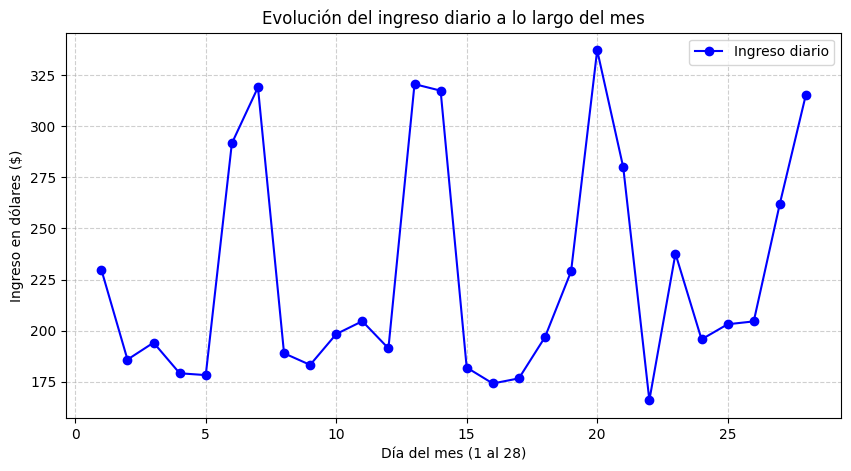

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Regeneramos los datos necesarios de la Parte 1 por si se reinició el kernel
rng = np.random.default_rng(42)
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])
dia_semana = np.tile(np.arange(7), 4)
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])
ventas_planas = rng.poisson(promedio).ravel()
ventas = ventas_planas.reshape(28, 5)
ingresos = ventas * precios
ingreso_diario = ingresos.sum(axis=1)

# Gráfico de líneas para ver la evolución a lo largo del mes
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, 29), ingreso_diario, marker='o', linestyle='-', color='b', label='Ingreso diario')

# Añadir título y etiquetas obligatorias
plt.title('Evolución del ingreso diario a lo largo del mes')
plt.xlabel('Día del mes (1 al 28)')
plt.ylabel('Ingreso en dólares ($)')

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

**Ejercicio 16.** Quiero comparar cuánto dinero generó cada producto en el mes.

Café: $1483.50
Latte: $2018.80
Té: $457.20
Croissant: $1114.00
Sándwich: $1269.00


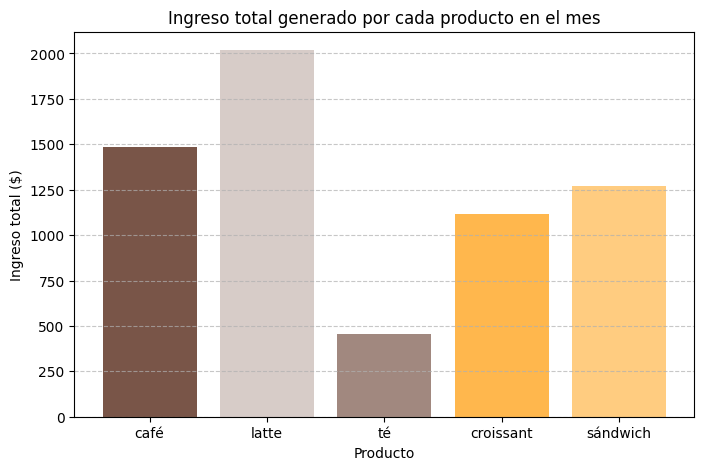

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Regeneramos los datos de la Parte 1 por si se reinició el kernel
rng = np.random.default_rng(42)
productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])
dia_semana = np.tile(np.arange(7), 4)
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])
ventas_planas = rng.poisson(promedio).ravel()
ventas = ventas_planas.reshape(28, 5)
ingresos = ventas * precios

# 1. Calcular cuánto dinero generó cada producto en todo el mes
ingreso_por_producto = ingresos.sum(axis=0)

# Mostrar los resultados en texto
for prod, ing in zip(productos, ingreso_por_producto):
    print(f"{prod.capitalize()}: ${ing:.2f}")

# 2. Crear un gráfico de barras para compararlos
plt.figure(figsize=(8, 5))
plt.bar(productos, ingreso_por_producto, color=['#795548', '#D7CCC8', '#A1887F', '#FFB74D', '#FFCC80'])

# Añadir título y etiquetas
plt.title('Ingreso total generado por cada producto en el mes')
plt.xlabel('Producto')
plt.ylabel('Ingreso total ($)')

# Mostrar el gráfico
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Ejercicio 17.** Quiero ver en un mismo gráfico las unidades vendidas cada día de los 5 productos, una línea por producto.

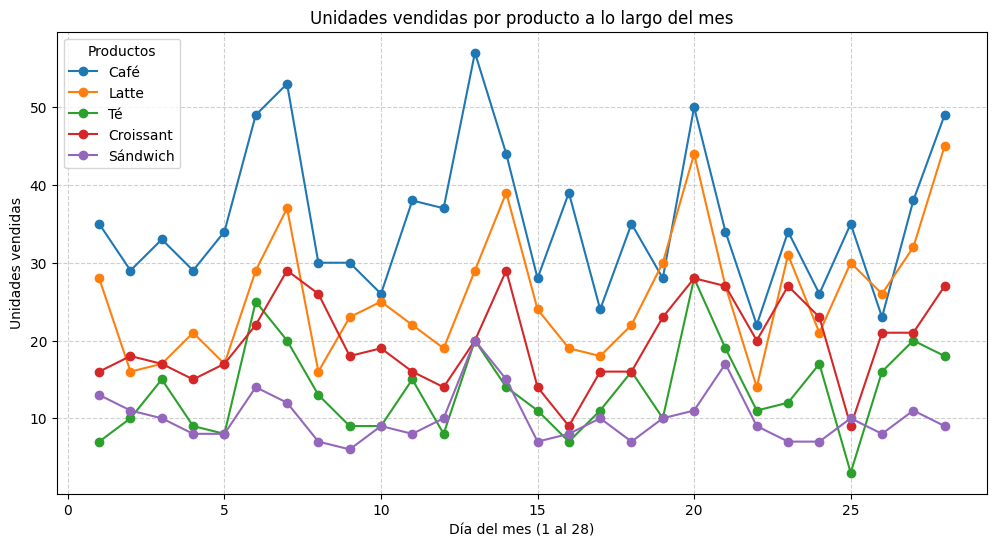

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Creamos el lienzo del gráfico
plt.figure(figsize=(12, 6))

# Eje X: Días del 1 al 28
dias = np.arange(1, 29)

# Iteramos sobre las 5 columnas de 'ventas' y los nombres de 'productos'
for i, producto in enumerate(productos):
    # ventas[:, i] selecciona todas las filas (días) para la columna i (producto)
    plt.plot(dias, ventas[:, i], marker='o', label=producto.capitalize())

# Añadimos detalles al gráfico
plt.title('Unidades vendidas por producto a lo largo del mes')
plt.xlabel('Día del mes (1 al 28)')
plt.ylabel('Unidades vendidas')

# Añadimos la leyenda para identificar qué color es cada producto
plt.legend(title='Productos')

# Añadimos la cuadrícula
plt.grid(True, linestyle='--', alpha=0.6)

# Mostramos el gráfico
plt.show()

**Ejercicio 18.** Quiero ver la matriz de ventas (días × productos) como un mapa de calor.

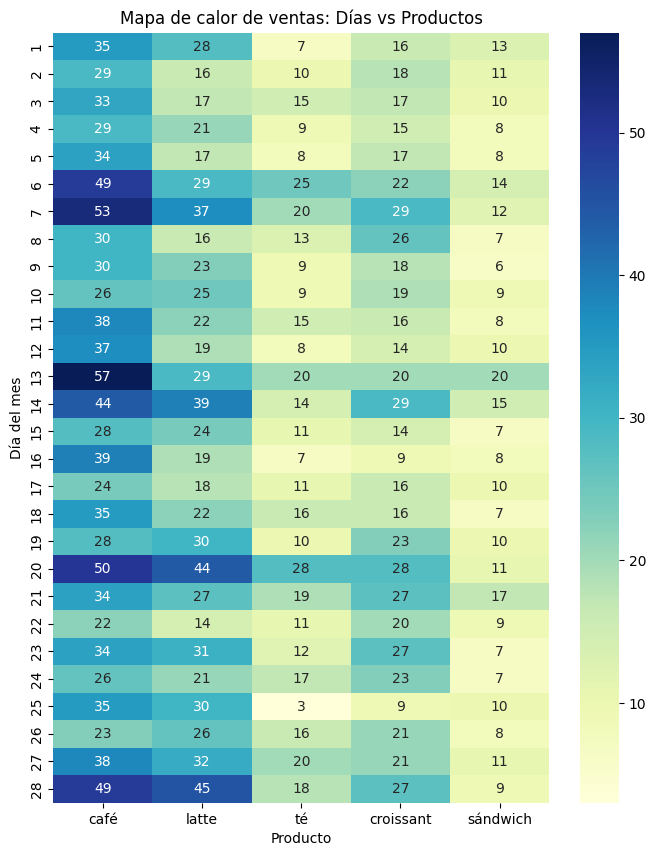

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuramos el tamaño del gráfico (más alto que ancho porque son 28 días)
plt.figure(figsize=(8, 10))

# Creamos el mapa de calor
# annot=True muestra los números dentro de las celdas
# fmt="d" asegura que los números se muestren como enteros
# cmap="YlGnBu" elige una paleta de colores (de amarillo a azul)
sns.heatmap(ventas, annot=True, fmt="d", cmap="YlGnBu",
            xticklabels=productos, yticklabels=np.arange(1, 29))

# Añadimos títulos y etiquetas
plt.title('Mapa de calor de ventas: Días vs Productos')
plt.xlabel('Producto')
plt.ylabel('Día del mes')

# Mostramos el gráfico
plt.show()

### Con los datos de las propinas 💵

Usa el DataFrame `propinas` tal como quedó al final de la Parte 2.

**Ejercicio 19.** Quiero ver el histograma del importe de la cuenta.

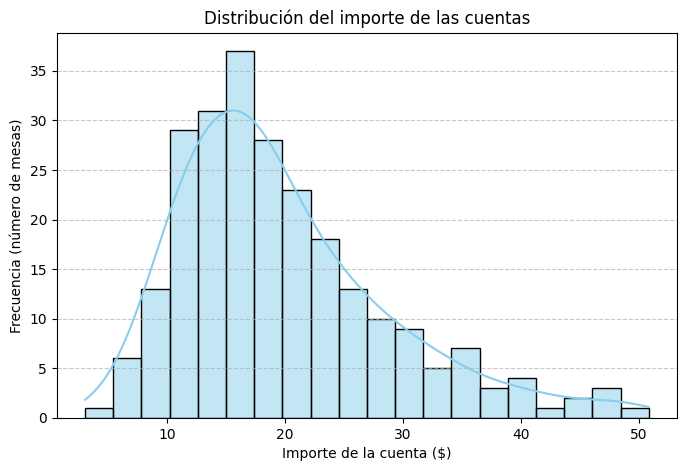

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el histograma usando seaborn
# kde=True añade la línea de la curva de tendencia
sns.histplot(data=propinas, x="cuenta", bins=20, kde=True, color="skyblue")

# Añadimos título y etiquetas
plt.title('Distribución del importe de las cuentas')
plt.xlabel('Importe de la cuenta ($)')
plt.ylabel('Frecuencia (número de mesas)')

# Mostramos el gráfico
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Ejercicio 20.** Quiero visualizar la relación entre la cuenta y la propina.

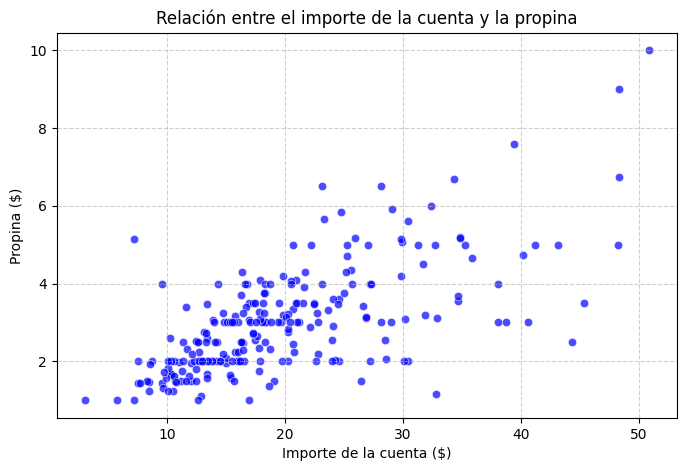

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el gráfico de dispersión
# alpha=0.7 hace que los puntos sean ligeramente transparentes para ver si se superponen
sns.scatterplot(data=propinas, x="cuenta", y="propina", color="blue", alpha=0.7)

# Añadimos título y etiquetas
plt.title('Relación entre el importe de la cuenta y la propina')
plt.xlabel('Importe de la cuenta ($)')
plt.ylabel('Propina ($)')

# Mostramos el gráfico con una cuadrícula
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Ejercicio 21.** Quiero ver esa misma relación, pero distinguiendo las comidas de las cenas.

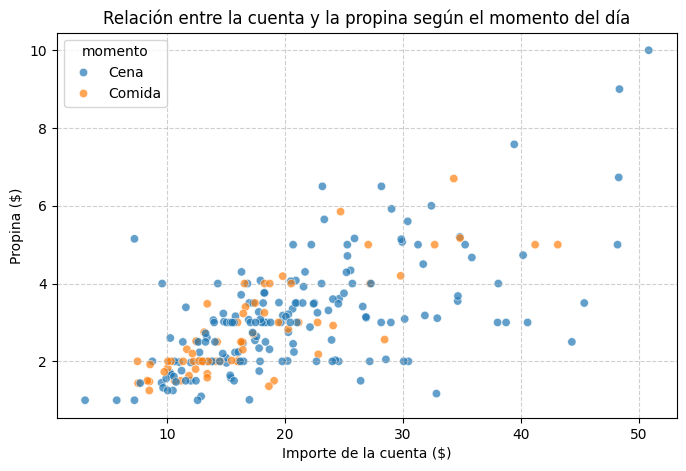

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el gráfico de dispersión usando 'hue' para pintar distinto cada 'momento'
sns.scatterplot(data=propinas, x="cuenta", y="propina", hue="momento", alpha=0.7)

# Añadimos título y etiquetas
plt.title('Relación entre la cuenta y la propina según el momento del día')
plt.xlabel('Importe de la cuenta ($)')
plt.ylabel('Propina ($)')

# Mostramos el gráfico
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Ejercicio 22.** Quiero ver si hay valores atípicos en el porcentaje de propina de cada día de la semana.

/tmp/ipykernel_2318/2280172617.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=propinas, x="dia", y="pct_propina", palette="Set2")


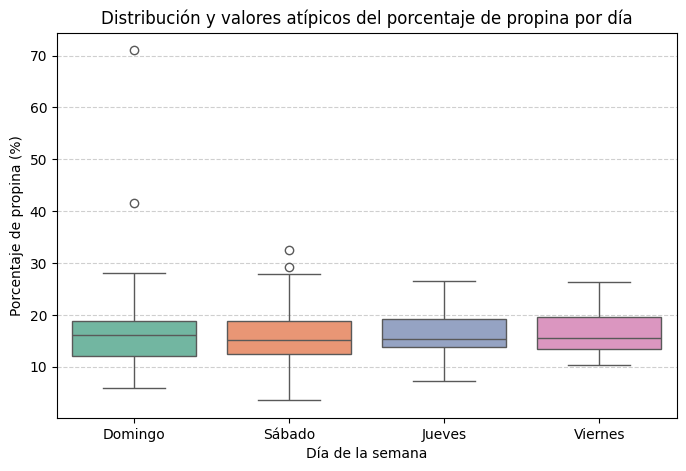

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el boxplot para ver la distribución y valores atípicos de pct_propina por día
sns.boxplot(data=propinas, x="dia", y="pct_propina", palette="Set2")

# Añadimos título y etiquetas
plt.title('Distribución y valores atípicos del porcentaje de propina por día')
plt.xlabel('Día de la semana')
plt.ylabel('Porcentaje de propina (%)')

# Mostramos el gráfico
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

**Ejercicio 23.** Quiero ver cuántas mesas se atendieron cada día.

/tmp/ipykernel_2318/1782060648.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=propinas, x="dia", order=orden_dias, palette="viridis")


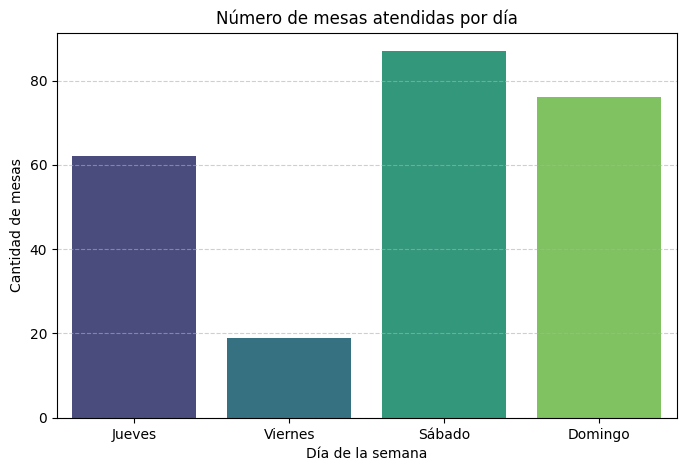

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el gráfico de conteo
# Opcional: puedes definir el orden para que aparezcan cronológicamente
orden_dias = ["Jueves", "Viernes", "Sábado", "Domingo"]
sns.countplot(data=propinas, x="dia", order=orden_dias, palette="viridis")

# Añadimos título y etiquetas
plt.title('Número de mesas atendidas por día')
plt.xlabel('Día de la semana')
plt.ylabel('Cantidad de mesas')

# Mostramos el gráfico
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

**Ejercicio 24.** Quiero comparar la propina media según el número de personas en la mesa, separando mesas de fumadores y de no fumadores.

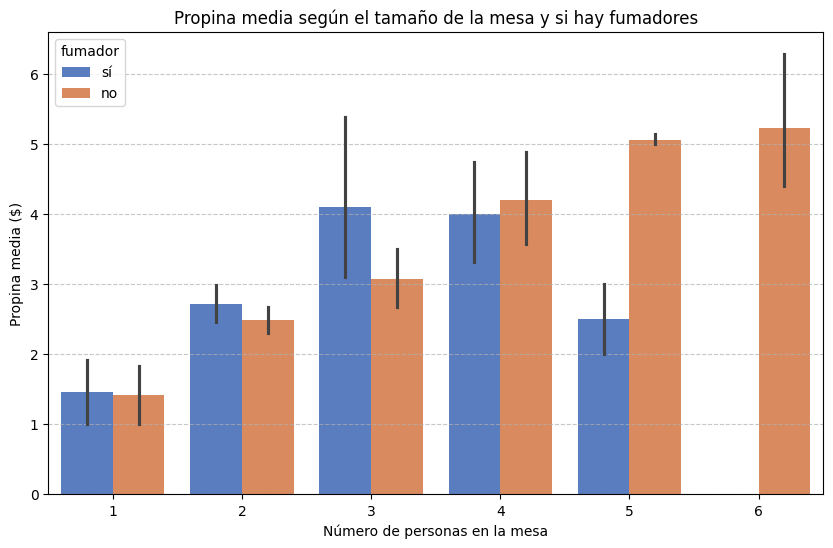

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(10, 6))

# Creamos el gráfico de barras
# x="personas" para el eje horizontal
# y="propina" (o "pct_propina" si prefieres ver el porcentaje) para calcular la media
# hue="fumador" para separar las barras por color
sns.barplot(data=propinas, x="personas", y="propina", hue="fumador", palette="muted")

# Añadimos título y etiquetas
plt.title('Propina media según el tamaño de la mesa y si hay fumadores')
plt.xlabel('Número de personas en la mesa')
plt.ylabel('Propina media ($)')

# Añadimos la cuadrícula
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mostramos el gráfico
plt.show()

### Con un dataset nuevo: los pingüinos 🐧

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies de la Antártida:

| Columna | Significado |
|---|---|
| `species` | especie: `Adelie`, `Chinstrap`, `Gentoo` |
| `island` | isla donde se registró |
| `bill_length_mm` | longitud del pico (mm) |
| `bill_depth_mm` | profundidad (altura) del pico (mm) |
| `flipper_length_mm` | longitud de la aleta (mm) |
| `body_mass_g` | peso (g) |
| `sex` | `Male` / `Female` |

**Ejercicio 25.** Carga los datos en un DataFrame llamado `pinguinos`. Quiero ver el histograma del peso de los pingüinos.

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


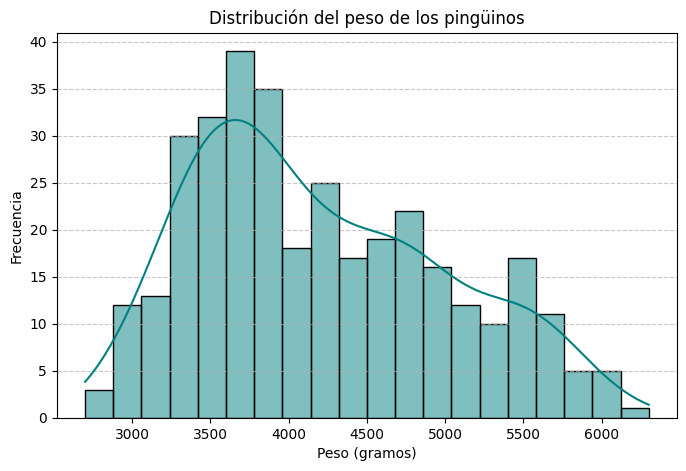

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar los datos en el DataFrame 'pinguinos'
# Usamos DATA_DIR que definiste al principio, o puedes poner simplemente "data/penguins.csv"
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv")

# Mostramos las primeras filas para verificar que cargó bien
display(pinguinos.head())

# 2. Crear el histograma del peso (body_mass_g)
plt.figure(figsize=(8, 5))
sns.histplot(data=pinguinos, x="body_mass_g", bins=20, kde=True, color="teal")

# Añadir título y etiquetas
plt.title('Distribución del peso de los pingüinos')
plt.xlabel('Peso (gramos)')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Ejercicio 26.** Quiero ver si la distribución del peso cambia según la especie.

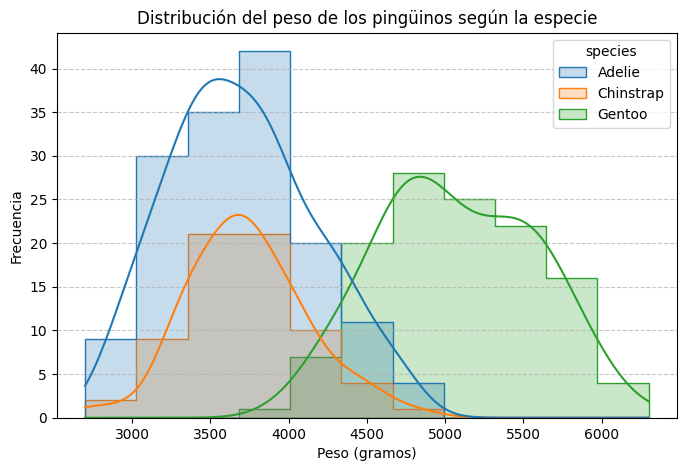

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el histograma separando por la columna "species"
# element="step" hace que las barras superpuestas se vean más limpias
sns.histplot(data=pinguinos, x="body_mass_g", hue="species", kde=True, element="step")

# Añadimos título y etiquetas
plt.title('Distribución del peso de los pingüinos según la especie')
plt.xlabel('Peso (gramos)')
plt.ylabel('Frecuencia')

# Mostramos el gráfico
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Ejercicio 27.** Quiero ver si hay valores atípicos en la longitud de la aleta de cada especie.

/tmp/ipykernel_2318/3562966891.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pinguinos, x="species", y="flipper_length_mm", palette="Set2")


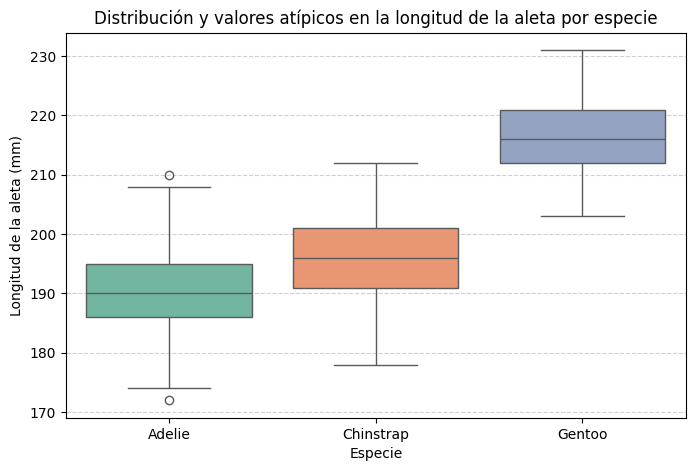

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el boxplot para la longitud de la aleta según la especie
sns.boxplot(data=pinguinos, x="species", y="flipper_length_mm", palette="Set2")

# Añadimos título y etiquetas
plt.title('Distribución y valores atípicos en la longitud de la aleta por especie')
plt.xlabel('Especie')
plt.ylabel('Longitud de la aleta (mm)')

# Mostramos el gráfico
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

**Ejercicio 28.** Quiero visualizar la relación entre la longitud y la profundidad del pico, distinguiendo las especies.

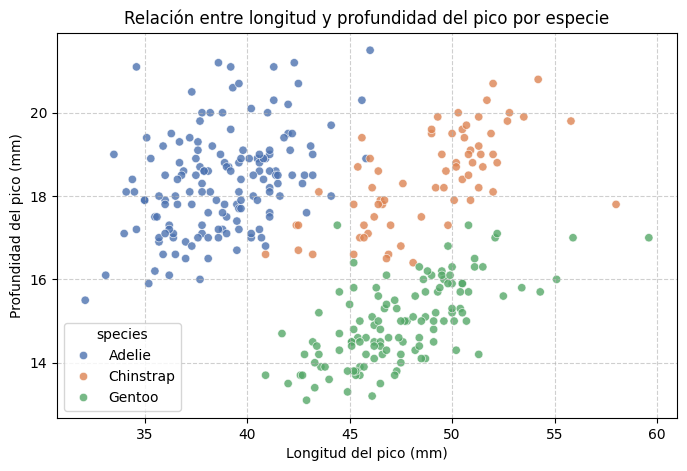

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el gráfico de dispersión usando 'hue' para separar por especie
sns.scatterplot(
    data=pinguinos,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    alpha=0.8,
    palette="deep"
)

# Añadimos título y etiquetas
plt.title('Relación entre longitud y profundidad del pico por especie')
plt.xlabel('Longitud del pico (mm)')
plt.ylabel('Profundidad del pico (mm)')

# Mostramos el gráfico con una cuadrícula ligera
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Ejercicio 29.** Quiero ver en una sola figura el histograma de las cuatro medidas numéricas, cada una en su propio gráfico.

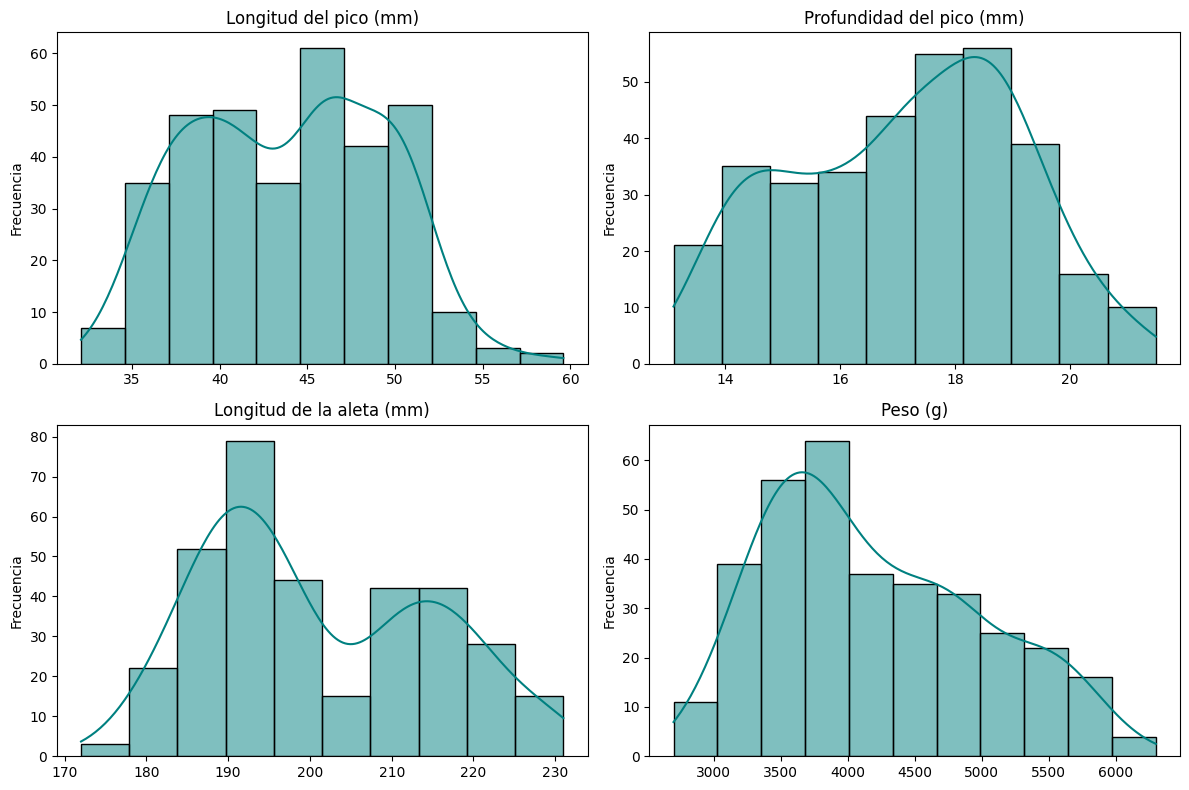

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos las columnas que queremos graficar y sus títulos en español
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
titulos = ["Longitud del pico (mm)", "Profundidad del pico (mm)", "Longitud de la aleta (mm)", "Peso (g)"]

# Creamos una figura con una cuadrícula de 2x2 (2 filas, 2 columnas)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Aplanamos la matriz de 'axes' para poder iterar sobre ella fácilmente
axes = axes.flatten()

# Usamos un bucle para crear un histograma en cada subgráfico
for i, col in enumerate(medidas):
    sns.histplot(data=pinguinos, x=col, kde=True, ax=axes[i], color="teal")
    axes[i].set_title(titulos[i])
    axes[i].set_xlabel("") # Limpiamos la etiqueta del eje X para que quede más limpio
    axes[i].set_ylabel("Frecuencia")

# Ajustamos el espaciado para que no se superpongan los textos
plt.tight_layout()
plt.show()

**Ejercicio 30.** Quiero ver qué medidas numéricas están más relacionadas entre sí.

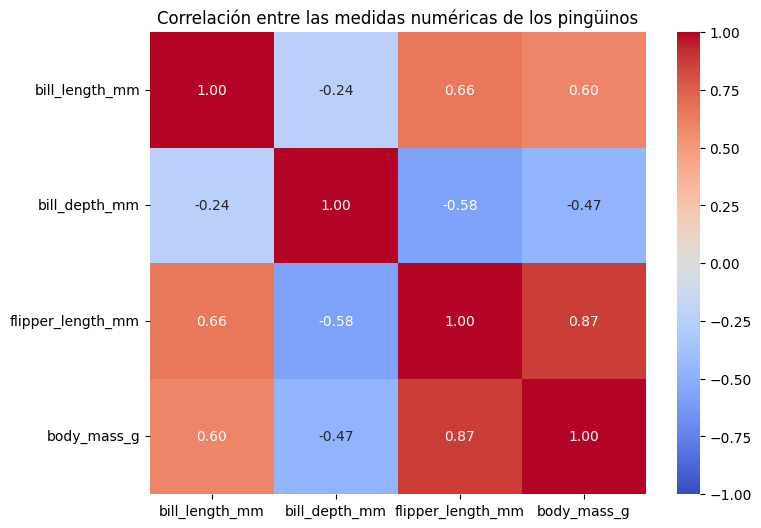

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 6))

# Seleccionamos solo las columnas numéricas del DataFrame
columnas_numericas = pinguinos.select_dtypes(include=['float64', 'int64'])

# Calculamos la matriz de correlación
correlacion = columnas_numericas.corr()

# Creamos el mapa de calor
# annot=True muestra el valor numérico, cmap elige la paleta de colores (rojo/azul)
# vmin=-1 y vmax=1 fijan la escala de colores para correlaciones (de -1 a 1)
sns.heatmap(correlacion, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)

# Añadimos título
plt.title('Correlación entre las medidas numéricas de los pingüinos')

# Mostramos el gráfico
plt.show()

**Ejercicio 31.** Quiero comparar el peso medio de cada especie, separando machos y hembras.

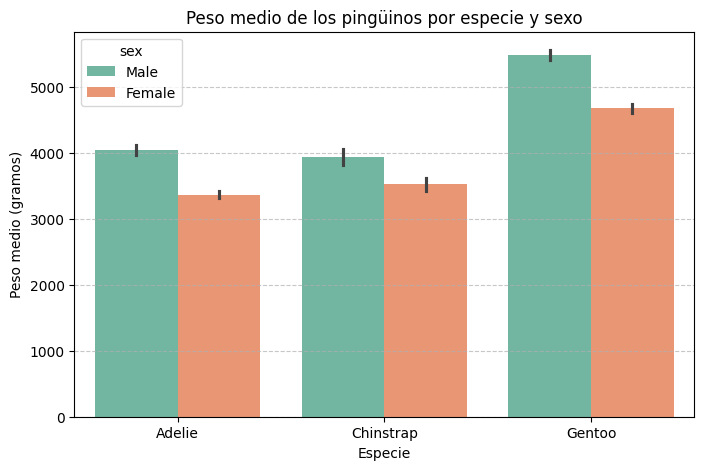

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creamos el gráfico de barras
# x="species" para agrupar por especie en el eje horizontal
# y="body_mass_g" para calcular el peso medio
# hue="sex" para separar las barras según machos y hembras
sns.barplot(data=pinguinos, x="species", y="body_mass_g", hue="sex", palette="Set2")

# Añadimos título y etiquetas
plt.title('Peso medio de los pingüinos por especie y sexo')
plt.xlabel('Especie')
plt.ylabel('Peso medio (gramos)')

# Añadimos la cuadrícula para facilitar la lectura
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mostramos el gráfico
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
